# 30 — GeoMAE-Inspired Next-Day Prediction
## Frozen spatiotemporal encoder + rolling linear probe vs LR13 and NodeGRU-L14

### Supervisor question
Can the GeoMAE-inspired representation also be used for **next-day hotspot prediction**, and how does it compare with the previous:
- LR13
- NodeGRU-L14

### Design

This notebook reuses the existing **NB24 GeoMAE-inspired spatiotemporal masked encoder**:

- 7 days
- 3 × 3 spatial neighborhood
- 63 tokens
- fire channels
- environmental channels
- wind speed + wind U/V are included in the token features

So spatial context and wind are genuinely present in the representation.

The encoder is **not trained directly on September labels**.
It was self-supervised-pretrained through July in NB24.

For next-day prediction:

```text
7-day × 3×3 fire + weather + wind context
                ↓
       frozen GeoMAE encoder
                ↓
     center-token representation
                ↓
 rolling Logistic Regression head
                ↓
       hotspot risk at t+1
```

For each September origin `t`:
- fit the downstream linear head only on forecast origins `<= t-1`;
- predict the center-cell hotspot label at `t+1`;
- merge the predictions with the already-generated LR13 and NodeGRU-L14 results from NB21.

### Important evaluation note

September has already been consumed by NB21.
Therefore this experiment is a **post-test exploratory comparison**, not a new untouched final test.

Primary metric remains **PR-AUC**.

In [12]:
# 1. Imports

from pathlib import Path
import warnings
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 260)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("DEVICE:", DEVICE)

DEVICE: cpu


In [13]:
# 2. Resolve project files

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    data_path = (
        root
        / "data"
        / "processed"
        / "regional_025"
        / "karhut_ml_dataset_regional_025.csv"
    )

    checkpoint_path = (
        root
        / "model_results"
        / "geomae_spatiotemporal"
        / "t2"
        / "models"
        / "geomae_inspired_encoder.pt"
    )

    nb21_pred_path = (
        root
        / "model_results"
        / "regional_025_final_test"
        / "t2"
        / "exports"
        / "final_september_predictions.csv"
    )

    if (
        data_path.exists()
        and checkpoint_path.exists()
        and nb21_pred_path.exists()
    ):
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the regional dataset, NB24 GeoMAE checkpoint, "
        "and NB21 final September predictions. "
        "Run NB24 and NB21 first, or set PROJECT_ROOT manually."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "regional_025"
    / "karhut_ml_dataset_regional_025.csv"
)

CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "geomae_spatiotemporal"
    / "t2"
    / "models"
    / "geomae_inspired_encoder.pt"
)

NB21_PRED_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_final_test"
    / "t2"
    / "exports"
    / "final_september_predictions.csv"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "geomae_nextday_rolling_probe"
    / "t2"
)

EXPORT_DIR = RESULT_DIR / "exports"
FIGURE_DIR = RESULT_DIR / "figures"

EXPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT  :", PROJECT_ROOT)
print("DATA_PATH     :", DATA_PATH)
print("CHECKPOINT    :", CHECKPOINT_PATH)
print("NB21 PRED     :", NB21_PRED_PATH)
print("RESULT_DIR    :", RESULT_DIR)

PROJECT_ROOT  : c:\Users\Asus\Documents\skripsi-karhut
DATA_PATH     : c:\Users\Asus\Documents\skripsi-karhut\data\processed\regional_025\karhut_ml_dataset_regional_025.csv
CHECKPOINT    : c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_spatiotemporal\t2\models\geomae_inspired_encoder.pt
NB21 PRED     : c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_final_test\t2\exports\final_september_predictions.csv
RESULT_DIR    : c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_nextday_rolling_probe\t2


In [14]:
# 3. Load NB24 checkpoint

try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
    )

TOKEN_FEATURES = list(
    checkpoint["token_features"]
)

FEATURE_MEAN = {
    k: float(v)
    for k, v in checkpoint["feature_mean"].items()
}

FEATURE_STD = {
    k: float(v)
    for k, v in checkpoint["feature_std"].items()
}

TEMPORAL_DAYS = int(
    checkpoint["temporal_days"]
)

SPATIAL_OFFSETS = [
    tuple(x)
    for x in checkpoint["spatial_offsets"]
]

CENTER_TOKEN_INDEX = int(
    checkpoint["center_token_index"]
)

PRETRAIN_END = pd.Timestamp(
    checkpoint["pretrain_end"]
)

GRID_STEP = 0.25
N_SPATIAL = len(SPATIAL_OFFSETS)
N_TOKENS = TEMPORAL_DAYS * N_SPATIAL

print("Token features :", TOKEN_FEATURES)
print("Temporal days  :", TEMPORAL_DAYS)
print("Spatial tokens :", N_SPATIAL)
print("Total tokens   :", N_TOKENS)
print("Pretrain end   :", PRETRAIN_END.date())
print("Center token   :", CENTER_TOKEN_INDEX)

Token features : ['temperature_mean', 'temperature_max', 'relative_humidity_mean', 'precipitation_sum', 'boundary_layer_height_mean', 'vapour_pressure_deficit_mean', 'wind_speed_mean', 'wind_speed_max', 'wind_u_mean', 'wind_v_mean', 'fire_active', 'fire_count_log1p', 'frp_sum_log1p']
Temporal days  : 7
Spatial tokens : 9
Total tokens   : 63
Pretrain end   : 2026-07-31
Center token   : 58


## Why this model already contains spatial + wind

NB24's input patch uses a **3×3 spatial neighborhood** over 7 days.
Its environmental token channels include:

- wind speed mean
- wind speed max
- wind U
- wind V

Therefore this downstream experiment is not temporal-only.

It is better described as:

> **GeoMAE-inspired spatiotemporal fire-environment encoder with wind context**

Wind here is learned from the token representation.
It is not the explicit hand-crafted wind-alignment rule from NB29D.

In [15]:
# 4. Load dataset and recreate NB24 transformed channels

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["date"],
)

df = (
    df
    .sort_values(["date", "cell_id"])
    .reset_index(drop=True)
)

df["fire_count_log1p"] = np.log1p(
    pd.to_numeric(
        df["fire_count"],
        errors="coerce",
    ).clip(lower=0)
)

df["frp_sum_log1p"] = np.log1p(
    pd.to_numeric(
        df["frp_sum"],
        errors="coerce",
    ).clip(lower=0)
)

required = {
    "date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "target_fire_active_t1",
    "active_days_prev3_incl_t",
    *TOKEN_FEATURES,
}

missing = sorted(
    required - set(df.columns)
)

if missing:
    raise ValueError(
        "Missing required columns:\n"
        + "\n".join(f"- {c}" for c in missing)
    )

print("Rows :", len(df))
print("Dates:", df["date"].min().date(), "→", df["date"].max().date())
print("Cells:", df["cell_id"].nunique())

Rows : 16625
Dates: 2026-05-08 → 2026-09-09
Cells: 133


In [16]:
# 5. Recreate NB24 normalization using checkpoint statistics

z_cols = []

for col in TOKEN_FEATURES:
    z_col = f"z__{col}"

    mean = FEATURE_MEAN[col]
    std = FEATURE_STD[col]

    if not np.isfinite(std) or std == 0:
        std = 1.0

    df[z_col] = (
        pd.to_numeric(
            df[col],
            errors="coerce",
        )
        - mean
    ) / std

    z_cols.append(z_col)

z_matrix = (
    df[z_cols]
    .to_numpy(dtype=np.float32)
)

valid_vector = np.isfinite(
    z_matrix
).all(axis=1)

print("Normalized matrix:", z_matrix.shape)
print("Valid rows:", int(valid_vector.sum()), "/", len(valid_vector))

Normalized matrix: (16625, 13)
Valid rows: 16625 / 16625


In [17]:
# 6. Fast lookup and sample metadata

work = df.copy()

work["lat_key"] = (
    work["grid_lat"]
    .round(3)
)

work["lon_key"] = (
    work["grid_lon"]
    .round(3)
)

row_lookup = {
    (
        pd.Timestamp(row.date),
        round(float(row.lat_key), 3),
        round(float(row.lon_key), 3),
    ): idx
    for idx, row
    in work[
        ["date", "lat_key", "lon_key"]
    ].iterrows()
}

min_sample_date = (
    work["date"].min()
    + pd.Timedelta(days=TEMPORAL_DAYS - 1)
)

META = (
    work[
        work["date"] >= min_sample_date
    ][
        [
            "date",
            "cell_id",
            "grid_lat",
            "grid_lon",
            "target_fire_active_t1",
            "active_days_prev3_incl_t",
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

print("Potential samples:", len(META))
print("Earliest sample :", META["date"].min().date())

Potential samples: 15827
Earliest sample : 2026-05-14


In [18]:
# 7. Patch builder

def build_patch(
    center_date,
    center_lat,
    center_lon,
):
    x = np.zeros(
        (
            N_TOKENS,
            len(TOKEN_FEATURES),
        ),
        dtype=np.float32,
    )

    valid = np.zeros(
        N_TOKENS,
        dtype=bool,
    )

    token_idx = 0

    for day_back in range(
        TEMPORAL_DAYS - 1,
        -1,
        -1,
    ):
        token_date = (
            pd.Timestamp(center_date)
            - pd.Timedelta(days=day_back)
        )

        for dx, dy in SPATIAL_OFFSETS:
            lat = round(
                float(
                    center_lat
                    + dy * GRID_STEP
                ),
                3,
            )

            lon = round(
                float(
                    center_lon
                    + dx * GRID_STEP
                ),
                3,
            )

            idx = row_lookup.get(
                (
                    token_date,
                    lat,
                    lon,
                )
            )

            if (
                idx is not None
                and valid_vector[idx]
            ):
                x[token_idx] = (
                    z_matrix[idx]
                )

                valid[token_idx] = True

            token_idx += 1

    return x, valid

In [19]:
# 8. Build patch tensor

patches = []
valid_masks = []
kept_meta = []

for row in META.itertuples(index=False):
    x, valid = build_patch(
        row.date,
        row.grid_lat,
        row.grid_lon,
    )

    # Current center token must exist.
    if not valid[CENTER_TOKEN_INDEX]:
        continue

    patches.append(x)
    valid_masks.append(valid)
    kept_meta.append(
        {
            "date": row.date,
            "cell_id": row.cell_id,
            "grid_lat": row.grid_lat,
            "grid_lon": row.grid_lon,
            "target_fire_active_t1": int(row.target_fire_active_t1),
            "active_days_prev3_incl_t": float(row.active_days_prev3_incl_t),
        }
    )

X = np.stack(
    patches
).astype(np.float32)

VALID = np.stack(
    valid_masks
).astype(bool)

META = pd.DataFrame(
    kept_meta
)

print("Patch tensor   :", X.shape)
print("Validity tensor:", VALID.shape)
print("Metadata rows  :", len(META))
print("Mean valid tokens/sample:", round(VALID.sum(axis=1).mean(), 2))

Patch tensor   : (15827, 63, 13)
Validity tensor: (15827, 63)
Metadata rows  : 15827
Mean valid tokens/sample: 55.53


In [20]:
# 9. Restore exact NB24 encoder

class SpatiotemporalMaskedEncoder(nn.Module):
    def __init__(
        self,
        n_features,
        d_model=64,
        nhead=4,
        num_layers=2,
        dim_feedforward=128,
        dropout=0.10,
    ):
        super().__init__()

        self.n_features = n_features
        self.d_model = d_model

        # Project original token features into Transformer hidden dimension
        self.input_proj = nn.Linear(
            n_features,
            d_model,
        )

        # Learnable token used when a token position is masked
        self.mask_token = nn.Parameter(
            torch.zeros(
                1,
                1,
                d_model,
            )
        )

        # Temporal position embedding
        self.time_embedding = nn.Embedding(
            TEMPORAL_DAYS,
            d_model,
        )

        # Spatial position embedding
        self.space_embedding = nn.Embedding(
            N_SPATIAL,
            d_model,
        )

        # Transformer encoder block
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
            norm_first=True,
            activation="gelu",
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
        )

        self.norm = nn.LayerNorm(
            d_model
        )

        # Reconstruction head used during masked pretraining
        self.reconstruction_head = nn.Linear(
            d_model,
            n_features,
        )

        # ---------------------------------------------------------
        # Rebuild temporal/spatial token-position indices
        # ---------------------------------------------------------

        token_time = []
        token_space = []

        for t in range(TEMPORAL_DAYS):
            for s in range(N_SPATIAL):
                token_time.append(t)
                token_space.append(s)

        # These buffers are deterministic metadata.
        # They are rebuilt from TEMPORAL_DAYS and N_SPATIAL,
        # so they do NOT need to be stored/restored in state_dict.
        self.register_buffer(
            "token_time",
            torch.tensor(
                token_time,
                dtype=torch.long,
            ),
            persistent=False,
        )

        self.register_buffer(
            "token_space",
            torch.tensor(
                token_space,
                dtype=torch.long,
            ),
            persistent=False,
        )

    def encode(
        self,
        x,
        valid_mask,
        mask_positions=None,
    ):
        # Project input features to hidden dimension
        h = self.input_proj(x)

        # Replace selected token positions with learnable mask token
        if mask_positions is not None:
            mask_token = self.mask_token.expand(
                x.shape[0],
                x.shape[1],
                -1,
            )

            h = torch.where(
                mask_positions.unsqueeze(-1),
                mask_token,
                h,
            )

        # Add temporal + spatial positional embeddings
        positional = (
            self.time_embedding(
                self.token_time
            )
            +
            self.space_embedding(
                self.token_space
            )
        )

        h = (
            h
            + positional.unsqueeze(0)
        )

        # Transformer encoding
        h = self.encoder(
            h,
            src_key_padding_mask=(
                ~valid_mask
            ),
        )

        return self.norm(h)

    def forward(
        self,
        x,
        valid_mask,
        mask_positions=None,
    ):
        h = self.encode(
            x,
            valid_mask,
            mask_positions,
        )

        recon = self.reconstruction_head(
            h
        )

        return recon, h


# -------------------------------------------------------------
# Restore architecture dimensions from the saved NB24 checkpoint
# -------------------------------------------------------------

state = checkpoint[
    "model_state_dict"
]

# Infer hidden dimension
D_MODEL = int(
    state[
        "input_proj.weight"
    ].shape[0]
)

# Infer feed-forward dimension
DIM_FEEDFORWARD = int(
    state[
        "encoder.layers.0.linear1.weight"
    ].shape[0]
)

# Infer number of Transformer layers
layer_numbers = []

for key in state:
    if key.startswith(
        "encoder.layers."
    ):
        parts = key.split(".")

        if len(parts) > 2:
            try:
                layer_numbers.append(
                    int(parts[2])
                )
            except ValueError:
                pass

NUM_LAYERS = (
    max(layer_numbers) + 1
    if layer_numbers
    else 2
)

# NB24 used four attention heads
NHEAD = 4


# -------------------------------------------------------------
# Rebuild the model using the exact saved architecture
# -------------------------------------------------------------

model = SpatiotemporalMaskedEncoder(
    n_features=len(TOKEN_FEATURES),
    d_model=D_MODEL,
    nhead=NHEAD,
    num_layers=NUM_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
).to(DEVICE)


# -------------------------------------------------------------
# Restore trained parameters
# -------------------------------------------------------------

model.load_state_dict(
    state
)

model.eval()


# -------------------------------------------------------------
# Sanity checks
# -------------------------------------------------------------

print("D_MODEL         :", D_MODEL)
print("NHEAD           :", NHEAD)
print("NUM_LAYERS      :", NUM_LAYERS)
print("DIM_FEEDFORWARD :", DIM_FEEDFORWARD)
print("TOKEN FEATURES  :", len(TOKEN_FEATURES))
print("TEMPORAL DAYS   :", TEMPORAL_DAYS)
print("N_SPATIAL       :", N_SPATIAL)
print("N_TOKENS        :", N_TOKENS)
print("CENTER TOKEN    :", CENTER_TOKEN_INDEX)
print()
print("✅ Encoder restored successfully.")

D_MODEL         : 64
NHEAD           : 4
NUM_LAYERS      : 2
DIM_FEEDFORWARD : 128
TOKEN FEATURES  : 13
TEMPORAL DAYS   : 7
N_SPATIAL       : 9
N_TOKENS        : 63
CENTER TOKEN    : 58

✅ Encoder restored successfully.


## Representation used for prediction

We use the **current center token's hidden representation**.

Why?
- target is next-day hotspot at the same center cell;
- after Transformer self-attention, that center representation can already attend to:
  - previous days,
  - neighboring cells,
  - weather,
  - wind channels.

No masking is applied at inference for the forecasting representation because all information through day `t` is available when predicting `t+1`.

In [21]:
# 10. Extract frozen GeoMAE center-token embeddings

class ArrayDataset(Dataset):
    def __init__(
        self,
        X,
        VALID,
    ):
        self.X = X
        self.VALID = VALID

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        return (
            torch.from_numpy(
                self.X[i]
            ),
            torch.from_numpy(
                self.VALID[i]
            ),
        )


dataset = ArrayDataset(
    X,
    VALID,
)

loader = DataLoader(
    dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0,
)

embeddings = []

with torch.no_grad():
    for x_batch, valid_batch in loader:
        x_batch = x_batch.to(
            DEVICE
        )

        valid_batch = valid_batch.to(
            DEVICE
        )

        mask_positions = torch.zeros_like(
            valid_batch,
            dtype=torch.bool,
        )

        h = model.encode(
            x_batch,
            valid_batch,
            mask_positions,
        )

        center_h = h[
            :,
            CENTER_TOKEN_INDEX,
            :
        ]

        embeddings.append(
            center_h.detach()
            .cpu()
            .numpy()
        )

EMB = np.concatenate(
    embeddings,
    axis=0,
)

print("Embedding matrix:", EMB.shape)

Embedding matrix: (15827, 64)


In [22]:
# 11. Load official NB21 prediction table

baseline = pd.read_csv(
    NB21_PRED_PATH,
    parse_dates=[
        "origin_date",
        "forecast_date",
    ],
)

required_baseline = {
    "origin_date",
    "forecast_date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "y_true",
    "active_days_prev3_incl_t",
    "is_emerging_eligible",
    "lr13_score",
    "nodegru_l14_score",
}

missing = sorted(
    required_baseline
    - set(baseline.columns)
)

if missing:
    raise ValueError(
        "NB21 prediction export is missing:\n"
        + "\n".join(f"- {c}" for c in missing)
    )

TEST_ORIGINS = np.array(
    sorted(
        baseline[
            "origin_date"
        ].unique()
    )
)

print("Rows:", len(baseline))
print(
    "Origins:",
    pd.Timestamp(TEST_ORIGINS.min()).date(),
    "→",
    pd.Timestamp(TEST_ORIGINS.max()).date(),
)

Rows: 1197
Origins: 2026-09-01 → 2026-09-09


In [23]:
# 12. Rolling linear probe on frozen GeoMAE embeddings

def make_probe():
    return Pipeline(
        [
            (
                "scaler",
                StandardScaler(),
            ),
            (
                "model",
                LogisticRegression(
                    class_weight="balanced",
                    max_iter=1500,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )


rolling_rows = []

for origin in TEST_ORIGINS:
    origin = pd.Timestamp(origin)

    train_mask = (
        META["date"]
        <= origin - pd.Timedelta(days=1)
    ).to_numpy()

    pred_mask = (
        META["date"]
        .eq(origin)
        .to_numpy()
    )

    X_train = EMB[
        train_mask
    ]

    y_train = (
        META.loc[
            train_mask,
            "target_fire_active_t1",
        ]
        .astype(int)
        .to_numpy()
    )

    X_pred = EMB[
        pred_mask
    ]

    pred_meta = (
        META.loc[
            pred_mask
        ]
        .copy()
        .reset_index(drop=True)
    )

    if len(X_pred) == 0:
        raise RuntimeError(
            f"No GeoMAE samples found for origin {origin.date()}."
        )

    probe = make_probe()

    probe.fit(
        X_train,
        y_train,
    )

    score = (
        probe.predict_proba(
            X_pred
        )[:, 1]
    )

    for i, row in pred_meta.iterrows():
        rolling_rows.append(
            {
                "origin_date": origin,
                "forecast_date": (
                    origin
                    + pd.Timedelta(days=1)
                ),
                "cell_id": row["cell_id"],
                "geomae_nextday_score": float(
                    score[i]
                ),
            }
        )

    print(
        origin.date(),
        "| train rows =",
        len(X_train),
        "| positives =",
        int(y_train.sum()),
        "| predicted cells =",
        len(X_pred),
    )

geomae_pred = pd.DataFrame(
    rolling_rows
)

print("GeoMAE rolling rows:", len(geomae_pred))

2026-09-01 | train rows = 14630 | positives = 2985 | predicted cells = 133
2026-09-02 | train rows = 14763 | positives = 3069 | predicted cells = 133
2026-09-03 | train rows = 14896 | positives = 3160 | predicted cells = 133
2026-09-04 | train rows = 15029 | positives = 3244 | predicted cells = 133
2026-09-05 | train rows = 15162 | positives = 3325 | predicted cells = 133
2026-09-06 | train rows = 15295 | positives = 3416 | predicted cells = 133
2026-09-07 | train rows = 15428 | positives = 3468 | predicted cells = 133
2026-09-08 | train rows = 15561 | positives = 3540 | predicted cells = 133
2026-09-09 | train rows = 15694 | positives = 3605 | predicted cells = 133
GeoMAE rolling rows: 1197


In [24]:
# 13. Merge GeoMAE predictions with LR13 and NodeGRU-L14

comparison = baseline.merge(
    geomae_pred,
    on=[
        "origin_date",
        "forecast_date",
        "cell_id",
    ],
    how="inner",
    validate="one_to_one",
)

print(
    "Merged rows:",
    len(comparison),
    "/ baseline rows:",
    len(baseline),
)

if len(comparison) != len(baseline):
    print(
        "WARNING: row count differs. Inspect missing GeoMAE patches before interpreting metrics."
    )

display(
    comparison[
        [
            "origin_date",
            "forecast_date",
            "cell_id",
            "y_true",
            "lr13_score",
            "nodegru_l14_score",
            "geomae_nextday_score",
        ]
    ].head()
)

Merged rows: 1197 / baseline rows: 1197


,origin_date,forecast_date,cell_id,y_true,lr13_score,nodegru_l14_score,geomae_nextday_score
0,2026-09-01,2026-09-02,regional025_10_22,1,0.999992,0.971133,0.992898
1,2026-09-01,2026-09-02,regional025_10_23,1,1.000000,0.974532,0.996414
2,2026-09-01,2026-09-02,regional025_10_24,1,1.000000,0.975214,0.986112
3,2026-09-01,2026-09-02,regional025_10_25,1,1.000000,0.976170,0.990459
4,2026-09-01,2026-09-02,regional025_10_26,1,0.999994,0.969548,0.992752


In [25]:
# 14. Metric helpers

def best_f1_threshold(
    y_true,
    score,
):
    y = np.asarray(
        y_true
    ).astype(int)

    s = np.asarray(
        score
    ).astype(float)

    precision, recall, thresholds = (
        precision_recall_curve(
            y,
            s,
        )
    )

    if len(thresholds) == 0:
        return 0.5

    f1 = (
        2
        * precision[:-1]
        * recall[:-1]
        / np.clip(
            precision[:-1]
            + recall[:-1],
            1e-12,
            None,
        )
    )

    return float(
        thresholds[
            int(np.nanargmax(f1))
        ]
    )


def metric_bundle(
    y_true,
    score,
    threshold=None,
):
    y = np.asarray(
        y_true
    ).astype(int)

    s = np.asarray(
        score
    ).astype(float)

    if threshold is None:
        threshold = 0.5

    pred = (
        s >= threshold
    ).astype(int)

    return {
        "Rows": len(y),
        "Positives": int(y.sum()),
        "Prevalence": float(y.mean()),
        "PR-AUC": float(
            average_precision_score(
                y,
                s,
            )
        ),
        "ROC-AUC": float(
            roc_auc_score(
                y,
                s,
            )
        )
        if len(np.unique(y)) == 2
        else np.nan,
        "Precision": float(
            precision_score(
                y,
                pred,
                zero_division=0,
            )
        ),
        "Recall": float(
            recall_score(
                y,
                pred,
                zero_division=0,
            )
        ),
        "F1": float(
            f1_score(
                y,
                pred,
                zero_division=0,
            )
        ),
        "Accuracy": float(
            accuracy_score(
                y,
                pred,
            )
        ),
        "Threshold": float(
            threshold
        ),
    }

## Threshold handling

For the main comparison, PR-AUC is threshold-free.

For thresholded metrics, this notebook reports a **descriptive best-F1 threshold on the comparison set** only to make behavior visible.

Do not call those thresholded metrics a new untouched final-test result.

The most defensible headline for the supervisor is:
- overall PR-AUC
- Emerging-eligible PR-AUC
- Persistent-context PR-AUC

In [26]:
# 15. Overall model comparison

model_specs = [
    (
        "LR13",
        "lr13_score",
    ),
    (
        "NodeGRU-L14",
        "nodegru_l14_score",
    ),
    (
        "GeoMAE-ST-Wind linear probe",
        "geomae_nextday_score",
    ),
]

overall_rows = []

for model_name, score_col in model_specs:
    threshold = best_f1_threshold(
        comparison["y_true"],
        comparison[score_col],
    )

    overall_rows.append(
        {
            "Model": model_name,
            **metric_bundle(
                comparison["y_true"],
                comparison[score_col],
                threshold,
            ),
        }
    )

overall = pd.DataFrame(
    overall_rows
)

display(
    overall.sort_values(
        "PR-AUC",
        ascending=False,
    )
)

,Model,Rows,Positives,Prevalence,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Threshold
0,LR13,1197,684,0.571429,0.888116,0.863457,0.784676,0.868421,0.824427,0.788638,0.753201
1,NodeGRU-L14,1197,684,0.571429,0.882435,0.865785,0.762936,0.926901,0.836964,0.793651,0.815600
2,GeoMAE-ST-Wind linear probe,1197,684,0.571429,0.862811,0.841017,0.764780,0.888889,0.822177,0.780284,0.777955


In [27]:
# 16. Emerging vs Persistent comparison

emerging_mask = (
    comparison[
        "active_days_prev3_incl_t"
    ].eq(0)
)

persistent_mask = (
    comparison[
        "active_days_prev3_incl_t"
    ].gt(0)
)

subgroup_rows = []

for model_name, score_col in model_specs:
    for context_name, mask in [
        (
            "Emerging-3 eligible",
            emerging_mask,
        ),
        (
            "Persistent-context",
            persistent_mask,
        ),
    ]:
        sub = comparison[
            mask
        ]

        subgroup_rows.append(
            {
                "Model": model_name,
                "Context": context_name,
                "Rows": len(sub),
                "Positives": int(
                    sub["y_true"].sum()
                ),
                "Prevalence": float(
                    sub["y_true"].mean()
                ),
                "PR-AUC": float(
                    average_precision_score(
                        sub["y_true"],
                        sub[score_col],
                    )
                )
                if sub["y_true"].sum() > 0
                else np.nan,
                "ROC-AUC": float(
                    roc_auc_score(
                        sub["y_true"],
                        sub[score_col],
                    )
                )
                if sub["y_true"].nunique() == 2
                else np.nan,
            }
        )

subgroups = pd.DataFrame(
    subgroup_rows
)

display(
    subgroups
)

,Model,Context,Rows,Positives,Prevalence,PR-AUC,ROC-AUC
0,LR13,Emerging-3 eligible,252,28,0.111111,0.289877,0.709104
1,LR13,Persistent-context,945,656,0.694180,0.897755,0.798609
2,NodeGRU-L14,Emerging-3 eligible,252,28,0.111111,0.326900,0.742506
3,NodeGRU-L14,Persistent-context,945,656,0.694180,0.891270,0.800337
4,GeoMAE-ST-Wind linear probe,Emerging-3 eligible,252,28,0.111111,0.138255,0.576212
5,GeoMAE-ST-Wind linear probe,Persistent-context,945,656,0.694180,0.874893,0.772834


In [28]:
# 17. Delta table: GeoMAE vs previous models

overall_lookup = (
    overall
    .set_index("Model")
)

sub_lookup = (
    subgroups
    .pivot(
        index="Model",
        columns="Context",
        values="PR-AUC",
    )
)

delta_rows = []

for baseline_name in [
    "LR13",
    "NodeGRU-L14",
]:
    delta_rows.append(
        {
            "Comparison": (
                "GeoMAE-ST-Wind linear probe"
                + " - "
                + baseline_name
            ),
            "Delta overall PR-AUC": (
                overall_lookup.loc[
                    "GeoMAE-ST-Wind linear probe",
                    "PR-AUC",
                ]
                - overall_lookup.loc[
                    baseline_name,
                    "PR-AUC",
                ]
            ),
            "Delta Emerging PR-AUC": (
                sub_lookup.loc[
                    "GeoMAE-ST-Wind linear probe",
                    "Emerging-3 eligible",
                ]
                - sub_lookup.loc[
                    baseline_name,
                    "Emerging-3 eligible",
                ]
            ),
            "Delta Persistent PR-AUC": (
                sub_lookup.loc[
                    "GeoMAE-ST-Wind linear probe",
                    "Persistent-context",
                ]
                - sub_lookup.loc[
                    baseline_name,
                    "Persistent-context",
                ]
            ),
        }
    )

deltas = pd.DataFrame(
    delta_rows
)

display(deltas)

,Comparison,Delta overall PR-AUC,Delta Emerging PR-AUC,Delta Persistent PR-AUC
0,GeoMAE-ST-Wind linear probe - LR13,-0.025305,-0.151622,-0.022862
1,GeoMAE-ST-Wind linear probe - NodeGRU-L14,-0.019624,-0.188645,-0.016377


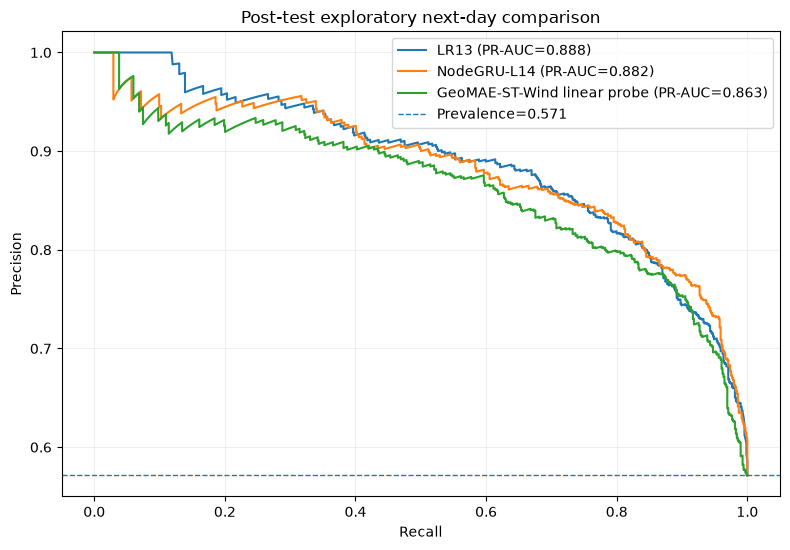

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_nextday_rolling_probe\t2\figures\01_geomae_vs_lr13_nodegru_pr_curve.png


In [29]:
# 18. Precision-Recall curves

fig, ax = plt.subplots(
    figsize=(8, 5.6)
)

for model_name, score_col in model_specs:
    p, r, _ = precision_recall_curve(
        comparison["y_true"],
        comparison[score_col],
    )

    pr = average_precision_score(
        comparison["y_true"],
        comparison[score_col],
    )

    ax.plot(
        r,
        p,
        label=f"{model_name} (PR-AUC={pr:.3f})",
    )

prevalence = float(
    comparison[
        "y_true"
    ].mean()
)

ax.axhline(
    prevalence,
    linestyle="--",
    linewidth=1,
    label=f"Prevalence={prevalence:.3f}",
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title(
    "Post-test exploratory next-day comparison"
)

ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

pr_path = (
    FIGURE_DIR
    / "01_geomae_vs_lr13_nodegru_pr_curve.png"
)

plt.savefig(
    pr_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", pr_path)

,forecast_date,Model,Positives,PR-AUC
0,2026-09-02,LR13,84,0.946325
1,2026-09-02,NodeGRU-L14,84,0.945209
2,2026-09-02,GeoMAE-ST-Wind linear probe,84,0.891446
3,2026-09-03,LR13,91,0.963455
4,2026-09-03,NodeGRU-L14,91,0.959028
5,2026-09-03,GeoMAE-ST-Wind linear probe,91,0.949073
6,2026-09-04,LR13,84,0.958127
7,2026-09-04,NodeGRU-L14,84,0.955441
8,2026-09-04,GeoMAE-ST-Wind linear probe,84,0.951430
9,2026-09-05,LR13,81,0.885124


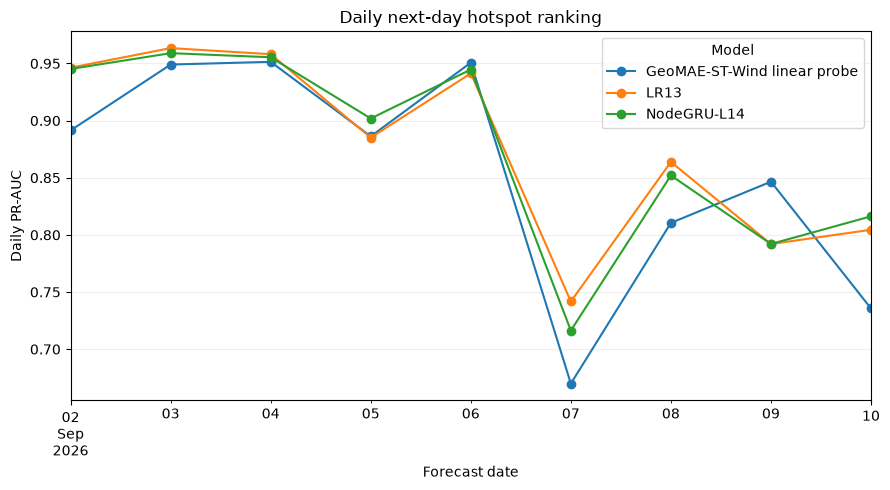

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_nextday_rolling_probe\t2\figures\02_daily_pr_auc_comparison.png


In [30]:
# 19. Daily PR-AUC comparison

daily_rows = []

for forecast_date, day in comparison.groupby(
    "forecast_date"
):
    for model_name, score_col in model_specs:
        if day["y_true"].sum() == 0:
            pr = np.nan
        else:
            pr = average_precision_score(
                day["y_true"],
                day[score_col],
            )

        daily_rows.append(
            {
                "forecast_date": forecast_date,
                "Model": model_name,
                "Positives": int(
                    day["y_true"].sum()
                ),
                "PR-AUC": pr,
            }
        )

daily = pd.DataFrame(
    daily_rows
)

display(daily)

pivot_daily = daily.pivot(
    index="forecast_date",
    columns="Model",
    values="PR-AUC",
)

ax = pivot_daily.plot(
    figsize=(9, 5),
    marker="o",
)

ax.set_ylabel("Daily PR-AUC")
ax.set_xlabel("Forecast date")
ax.set_title(
    "Daily next-day hotspot ranking"
)

ax.grid(alpha=0.2)

plt.tight_layout()

daily_path = (
    FIGURE_DIR
    / "02_daily_pr_auc_comparison.png"
)

plt.savefig(
    daily_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", daily_path)

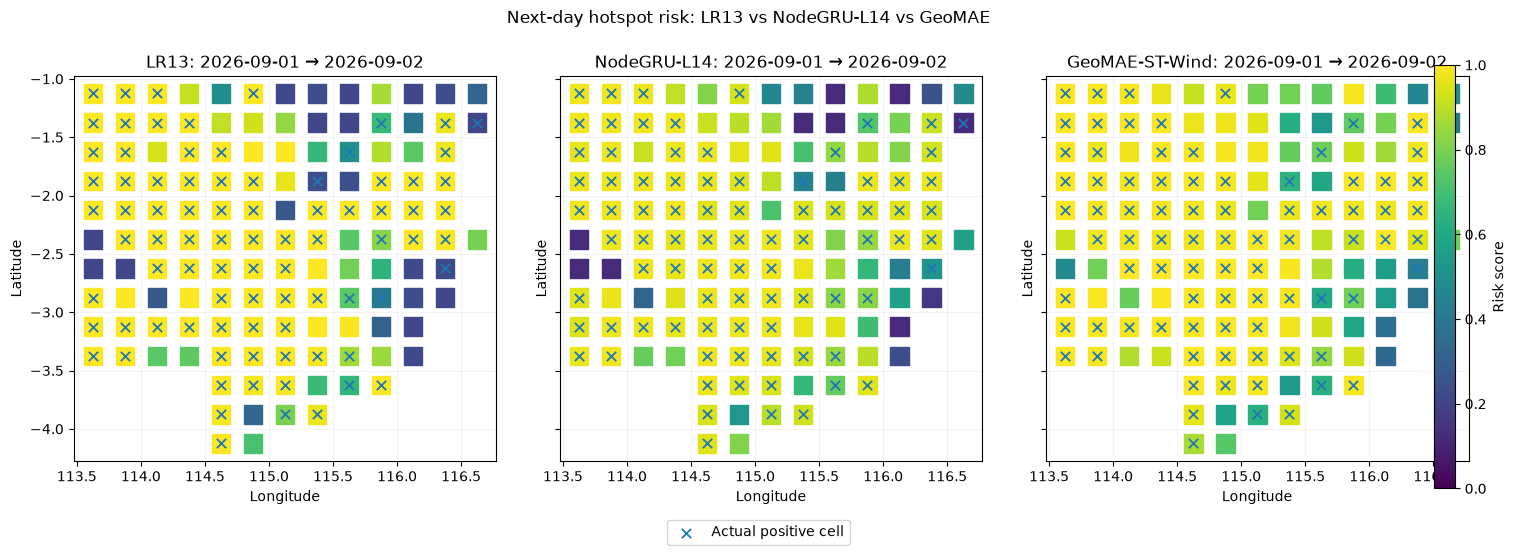

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_nextday_rolling_probe\t2\figures\03_sep02_three_model_risk_map.png


In [31]:
# 20. One map comparable to the previous LR13 / NodeGRU figure

MAP_FORECAST_DATE = pd.Timestamp(
    "2026-09-02"
)

day_map = comparison[
    comparison["forecast_date"].eq(
        MAP_FORECAST_DATE
    )
].copy()

if day_map.empty:
    raise ValueError(
        f"No rows for forecast date {MAP_FORECAST_DATE.date()}."
    )

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5.5),
    sharex=True,
    sharey=True,
)

map_specs = [
    (
        axes[0],
        "lr13_score",
        "LR13",
    ),
    (
        axes[1],
        "nodegru_l14_score",
        "NodeGRU-L14",
    ),
    (
        axes[2],
        "geomae_nextday_score",
        "GeoMAE-ST-Wind",
    ),
]

for ax, score_col, title in map_specs:
    sc = ax.scatter(
        day_map["grid_lon"],
        day_map["grid_lat"],
        c=day_map[score_col],
        marker="s",
        s=180,
        vmin=0,
        vmax=1,
    )

    actual = day_map[
        day_map["y_true"].eq(1)
    ]

    ax.scatter(
        actual["grid_lon"],
        actual["grid_lat"],
        marker="x",
        s=45,
        linewidths=1.3,
        label="Actual positive cell",
    )

    ax.set_title(
        (
            f"{title}: "
            f"{day_map['origin_date'].iloc[0].date()}"
            f" → {MAP_FORECAST_DATE.date()}"
        )
    )

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(alpha=0.15)

fig.colorbar(
    sc,
    ax=axes.ravel().tolist(),
    fraction=0.025,
    pad=0.02,
    label="Risk score",
)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
)

fig.suptitle(
    "Next-day hotspot risk: LR13 vs NodeGRU-L14 vs GeoMAE"
)

fig.subplots_adjust(
    bottom=0.16,
    top=0.86,
    wspace=0.15,
)

map_path = (
    FIGURE_DIR
    / "03_sep02_three_model_risk_map.png"
)

plt.savefig(
    map_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", map_path)

In [32]:
# 21. Export

comparison.to_csv(
    EXPORT_DIR
    / "september_geomae_lr13_nodegru_predictions.csv",
    index=False,
)

overall.to_csv(
    EXPORT_DIR
    / "overall_model_comparison.csv",
    index=False,
)

subgroups.to_csv(
    EXPORT_DIR
    / "subgroup_model_comparison.csv",
    index=False,
)

deltas.to_csv(
    EXPORT_DIR
    / "geomae_model_deltas.csv",
    index=False,
)

daily.to_csv(
    EXPORT_DIR
    / "daily_model_comparison.csv",
    index=False,
)

print("Saved outputs to:", EXPORT_DIR)

Saved outputs to: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_nextday_rolling_probe\t2\exports


In [ ]:
# 22. Automatic supervisor summary

geo_overall = float(
    overall_lookup.loc[
        "GeoMAE-ST-Wind linear probe",
        "PR-AUC",
    ]
)

geo_emerging = float(
    sub_lookup.loc[
        "GeoMAE-ST-Wind linear probe",
        "Emerging-3 eligible",
    ]
)

geo_persistent = float(
    sub_lookup.loc[
        "GeoMAE-ST-Wind linear probe",
        "Persistent-context",
    ]
)

print("=== NB30 GEOMAE NEXT-DAY EXPLORATORY COMPARISON ===")
print()
print("Representation : frozen NB24 GeoMAE spatiotemporal encoder")
print("Input          : 7 days × 3×3 neighborhood")
print("Wind           : included via wind speed + U/V token channels")
print("Downstream     : rolling Logistic Regression linear probe")
print("Target         : center-cell hotspot at t+1")
print("Evaluation     : same September rows as NB21")
print("Status         : post-test exploratory comparison")
print()
print("GeoMAE overall PR-AUC    :", round(geo_overall, 6))
print("GeoMAE Emerging PR-AUC   :", round(geo_emerging, 6))
print("GeoMAE Persistent PR-AUC :", round(geo_persistent, 6))
print()
print("MODEL DELTAS")
display(deltas)
print()
print("INTERPRETATION")
print("- Positive delta means GeoMAE ranked next-day hotspots better than the comparator.")
print("- Do not call raw scores calibrated probabilities.")
print("- Do not call this a new untouched final test because September was already used in NB21.")

=== NB30 GEOMAE NEXT-DAY EXPLORATORY COMPARISON ===

Representation : frozen NB24 GeoMAE spatiotemporal encoder
Input          : 7 days × 3×3 neighborhood
Wind           : included via wind speed + U/V token channels
Downstream     : rolling Logistic Regression linear probe
Target         : center-cell hotspot at t+1
Evaluation     : same September rows as NB21
Status         : post-test exploratory comparison

GeoMAE overall PR-AUC    : 0.862811
GeoMAE Emerging PR-AUC   : 0.138255
GeoMAE Persistent PR-AUC : 0.874893

MODEL DELTAS


,Comparison,Delta overall PR-AUC,Delta Emerging PR-AUC,Delta Persistent PR-AUC
0,GeoMAE-ST-Wind linear probe - LR13,-0.025305,-0.151622,-0.022862
1,GeoMAE-ST-Wind linear probe - NodeGRU-L14,-0.019624,-0.188645,-0.016377



INTERPRETATION
- Positive delta means GeoMAE ranked next-day hotspots better than the comparator.
- Do not call raw scores calibrated probabilities.
- Do not call this a new untouched final test because September was already used in NB21.


: 

# What to send back after Run All

Send these outputs:

1. **Section 15 — overall comparison**
2. **Section 16 — Emerging vs Persistent comparison**
3. **Section 17 — delta table**
4. **Section 18 — PR curve**
5. **Section 20 — September 2 three-model map**
6. **Section 22 — automatic summary**

Then we can decide whether the next experiment should be:

- keep the existing NB24 spatial + wind representation;
- or run a cleaner `ST_FIRE` vs `ST_FIRE_WIND` ablation for forecasting.

Do not tune on September based on the result.